In [1]:
import common as cm
import os
import pandas as pd
import numpy as np

In [2]:
# Read full AUC matrix (rows = target ICD, columns = "<candidate ICD>_<method>")
aou_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "aou_auc_landscape_full_matrix.csv"), index_col=0)
cand_disease = aou_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
aou_pmatrix = aou_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

# Keep top-10 AUCs per row, set all others (including NaN) to 0
row_rank = aou_pmatrix.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
aou_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# Sanity check: same rows, one column per candidate disease
print(aou_full_auc_matrix.shape, "->", aou_pmatrix.shape)

ukb_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "ukb_auc_landscape_full_matrix.csv"), index_col=0)
cand_disease = ukb_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
ukb_pmatrix = ukb_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

# Keep top-10 AUCs per row, set all others (including NaN) to 0
row_rank = ukb_pmatrix.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
ukb_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# Sanity check: same rows, one column per candidate disease
print(ukb_full_auc_matrix.shape, "->", ukb_pmatrix.shape)

afr_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "afr_auc_landscape_full_matrix.csv"), index_col=0)
cand_disease = afr_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
afr_pmatrix = afr_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

# Keep top-10 AUCs per row, set all others (including NaN) to 0
row_rank = afr_pmatrix.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
afr_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# Sanity check: same rows, one column per candidate disease
print(afr_full_auc_matrix.shape, "->", afr_pmatrix.shape)

aou_bmatrix = (aou_pmatrix > 0).astype(int)
ukb_bmatrix = (ukb_pmatrix > 0).astype(int)
afr_bmatrix = (afr_pmatrix > 0).astype(int)

(428, 1280) -> (428, 428)
(368, 1101) -> (368, 368)
(138, 414) -> (138, 138)


In [3]:
### Fix overlap disease sets BEFORE top-10 ranking ###
# Restricting only the bimatrix is not enough: the top-10 ranks in Cell 6 were computed against the full candidate pool
# (e.g. 428 in AoU EUR), so AoU-only candidates could occupy top-10 slots. Here both targets (rows) and candidates
# (columns) are restricted to the overlap set and the top-10 ranking is redone within that restricted pool.
# The heatmaps above (Fig 2e / Fig 4a) still use the full aou/ukb/afr_pmatrix and are not affected.

# Collapse the three PRS methods to one column per candidate disease (best AUC), same as Cell 6
cand_disease = aou_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
aou_disease_auc = aou_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

cand_disease = ukb_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
ukb_disease_auc = ukb_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

cand_disease = afr_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
afr_disease_auc = afr_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

# Overlap sets: a disease must be both a target (row) and a candidate (column) in each cohort being compared
aou_icd = set(aou_disease_auc.index.astype(str)) & set(aou_disease_auc.columns.astype(str))
ukb_icd = set(ukb_disease_auc.index.astype(str)) & set(ukb_disease_auc.columns.astype(str))
afr_icd = set(afr_disease_auc.index.astype(str)) & set(afr_disease_auc.columns.astype(str))

eur_overlap = sorted(aou_icd & ukb_icd)       # AoU EUR vs UKB EUR (expected 368)
eur_afr_overlap = sorted(aou_icd & afr_icd)   # AoU EUR vs AoU AFR (expected 97)
print("AoU EUR ∩ UKB EUR:", len(eur_overlap))
print("AoU EUR ∩ AoU AFR:", len(eur_afr_overlap))

# AoU EUR on the EUR overlap set: subset rows and columns, then re-rank top-10 within the restricted pool
sub_auc = aou_disease_auc.loc[eur_overlap, eur_overlap]
row_rank = sub_auc.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
aou_pmatrix_ov = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# UKB EUR on the EUR overlap set
sub_auc = ukb_disease_auc.loc[eur_overlap, eur_overlap]
row_rank = sub_auc.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
ukb_pmatrix_ov = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# AoU AFR on the EUR-AFR overlap set
sub_auc = afr_disease_auc.loc[eur_afr_overlap, eur_afr_overlap]
row_rank = sub_auc.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
afr_pmatrix_ov = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# AoU EUR on the EUR-AFR overlap set (EUR counterpart for the EUR vs AFR comparison)
sub_auc = aou_disease_auc.loc[eur_afr_overlap, eur_afr_overlap]
row_rank = sub_auc.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
aou_afr_pmatrix_ov = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# Keep the full-set binary matrices for reference, then overwrite the names used by the clustering cells below
aou_bmatrix_full = aou_bmatrix.copy()
ukb_bmatrix_full = ukb_bmatrix.copy()
afr_bmatrix_full = afr_bmatrix.copy()

aou_bmatrix = (aou_pmatrix_ov > 0).astype(int)
ukb_bmatrix = (ukb_pmatrix_ov > 0).astype(int)
afr_bmatrix = (afr_pmatrix_ov > 0).astype(int)
aou_afr_bmatrix = (aou_afr_pmatrix_ov > 0).astype(int)

# Sanity checks: square, identical row/column order, and the paired cohorts share the same disease order
assert list(aou_bmatrix.index) == list(aou_bmatrix.columns) == list(ukb_bmatrix.index) == list(ukb_bmatrix.columns)
assert list(afr_bmatrix.index) == list(afr_bmatrix.columns) == list(aou_afr_bmatrix.index) == list(aou_afr_bmatrix.columns)
print("AoU EUR:", aou_bmatrix.shape, "| UKB EUR:", ukb_bmatrix.shape, "| AoU AFR:", afr_bmatrix.shape, "| AoU EUR (AFR overlap):", aou_afr_bmatrix.shape)

# Every target should still have 10 selected candidates after re-ranking (fewer only if AUCs are missing)
print("Targets with <10 selected — AoU:", (aou_bmatrix.sum(axis=1) < 10).sum(), "UKB:", (ukb_bmatrix.sum(axis=1) < 10).sum(),
      "AFR:", (afr_bmatrix.sum(axis=1) < 10).sum(), "AoU (AFR overlap):", (aou_afr_bmatrix.sum(axis=1) < 10).sum())

AoU EUR ∩ UKB EUR: 368
AoU EUR ∩ AoU AFR: 97
AoU EUR: (368, 368) | UKB EUR: (368, 368) | AoU AFR: (97, 97) | AoU EUR (AFR overlap): (97, 97)
Targets with <10 selected — AoU: 0 UKB: 0 AFR: 0 AoU (AFR overlap): 0


# Heatmap (AoU-UKB EUR)

In [4]:
aou_smatrix = aou_bmatrix.copy()
ukb_smatrix = ukb_bmatrix.copy()
print(ukb_smatrix.shape, aou_smatrix.shape)

(368, 368) (368, 368)


In [5]:
### Construct Bidirectional-matrix ###

A = aou_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
aou_bimatrix = pd.DataFrame(M_bi, index=aou_bmatrix.index, columns=aou_bmatrix.index)

A = ukb_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
ukb_bimatrix = pd.DataFrame(M_bi, index=ukb_bmatrix.index, columns=ukb_bmatrix.index)

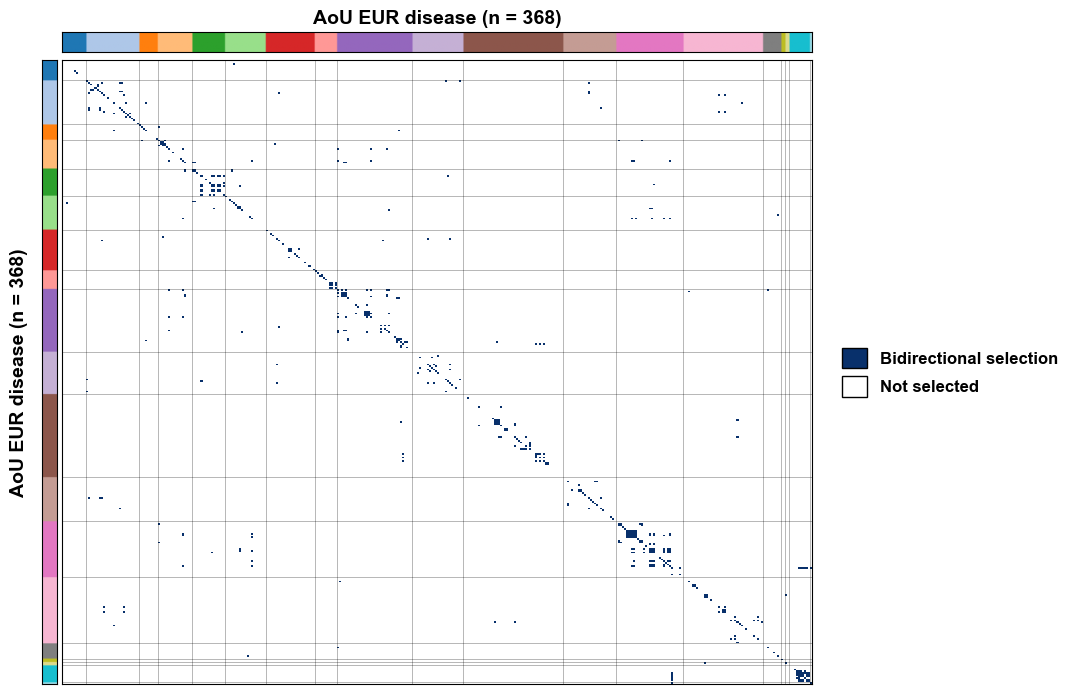

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

row_icd = list(aou_bimatrix.index)
col_icd = list(aou_bimatrix.columns)

row_chapters = [cm.assign_chapter(icd) for icd in row_icd]
col_chapters = [cm.assign_chapter(icd) for icd in col_icd]

row_colors = [cm.chapter2color_map.get(ch) for ch in row_chapters]
col_colors = [cm.chapter2color_map.get(ch) for ch in col_chapters]

# Figure layout
fig = plt.figure(figsize=(10, 8))

ax_colstrip = fig.add_axes([0.09, 0.91, 0.75, 0.025])
ax_rowstrip = fig.add_axes([0.07, 0.12, 0.015, 0.78])
ax_hm       = fig.add_axes([0.09, 0.12, 0.75, 0.78])
# ax_cbar     = fig.add_axes([0.86, 0.22, 0.02, 0.60])

# Row chapter color strip
row_strip_array = np.array([mcolors.to_rgba(c) for c in row_colors]).reshape(len(row_icd), 1, 4)
ax_rowstrip.imshow(row_strip_array, aspect="auto", origin="upper")

ax_rowstrip.set_xticks([])
ax_rowstrip.set_yticks([])
ax_rowstrip.set_ylabel(f"AoU EUR disease (n = {len(row_icd)})", fontsize=14, fontweight="bold", labelpad=10)

# Column chapter color strip
col_strip_array = np.array([mcolors.to_rgba(c) for c in col_colors]).reshape(1, len(col_icd), 4)
ax_colstrip.imshow(col_strip_array, aspect="auto", origin="upper")

ax_colstrip.set_xticks([])
ax_colstrip.set_yticks([])
ax_colstrip.set_title(f"AoU EUR disease (n = {len(col_icd)})", fontsize=14, fontweight="bold", pad=6)

bi_color = "#08306B"
cmap_bin = mcolors.ListedColormap(["white", bi_color])

# Heatmap
sns.heatmap((aou_bimatrix > 0).astype(int), cmap=cmap_bin, vmin=0, vmax=1, ax=ax_hm,
            xticklabels=False, yticklabels=False, cbar=False, rasterized=True)
ax_hm.set_xlabel("")
ax_hm.set_ylabel("")

for _, spine in ax_hm.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Chapter boundaries
row_boundaries = [i for i in range(1, len(row_chapters)) if row_chapters[i] != row_chapters[i - 1]]
col_boundaries = [i for i in range(1, len(col_chapters)) if col_chapters[i] != col_chapters[i - 1]]

for b in row_boundaries:
    ax_hm.axhline(b, color="black", linewidth=0.4, alpha=0.5)

for b in col_boundaries:
    ax_hm.axvline(b, color="black", linewidth=0.4, alpha=0.5)

# Legend: two categories, placed to the right of the heatmap
legend_handles = [
    mpatches.Patch(facecolor=bi_color, edgecolor="black", linewidth=1, label="Bidirectional selection"),
    mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1, label="Not selected"),
]
leg = ax_hm.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
                   frameon=False, fontsize=12, handlelength=1.5, handleheight=1.5)
for text in leg.get_texts():
    text.set_fontweight("bold")

plt.show()

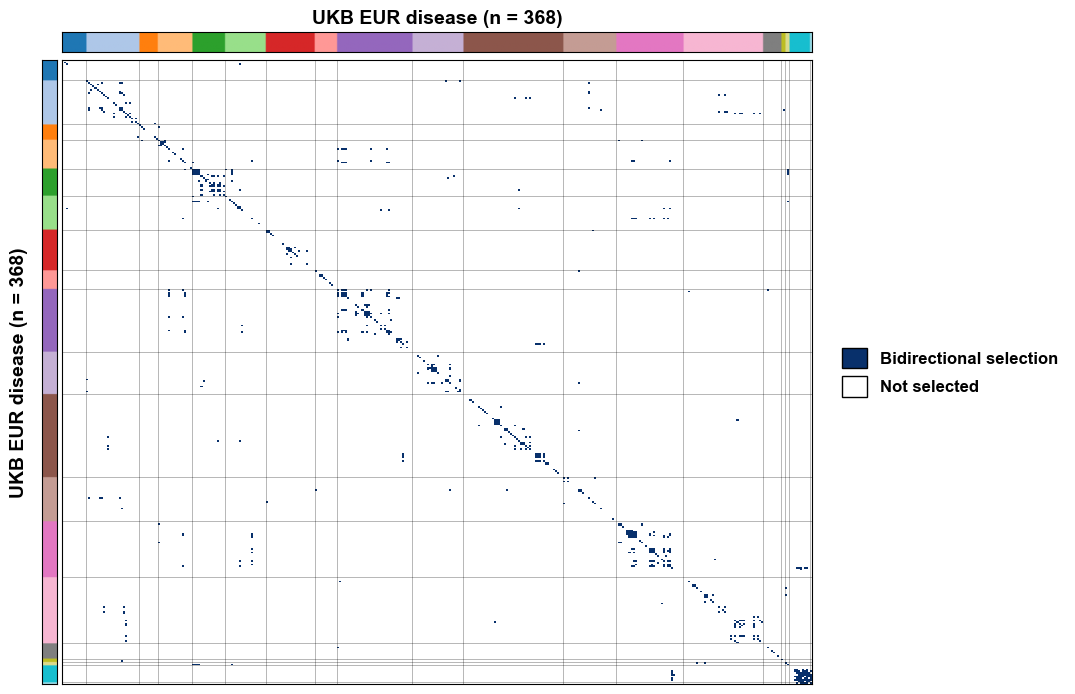

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

row_icd = list(ukb_bimatrix.index)
col_icd = list(ukb_bimatrix.columns)

row_chapters = [cm.assign_chapter(icd) for icd in row_icd]
col_chapters = [cm.assign_chapter(icd) for icd in col_icd]

row_colors = [cm.chapter2color_map.get(ch) for ch in row_chapters]
col_colors = [cm.chapter2color_map.get(ch) for ch in col_chapters]

# Figure layout
fig = plt.figure(figsize=(10, 8))

ax_colstrip = fig.add_axes([0.09, 0.91, 0.75, 0.025])
ax_rowstrip = fig.add_axes([0.07, 0.12, 0.015, 0.78])
ax_hm       = fig.add_axes([0.09, 0.12, 0.75, 0.78])
# ax_cbar     = fig.add_axes([0.86, 0.22, 0.02, 0.60])

# Row chapter color strip
row_strip_array = np.array([mcolors.to_rgba(c) for c in row_colors]).reshape(len(row_icd), 1, 4)
ax_rowstrip.imshow(row_strip_array, aspect="auto", origin="upper")

ax_rowstrip.set_xticks([])
ax_rowstrip.set_yticks([])
ax_rowstrip.set_ylabel(f"UKB EUR disease (n = {len(row_icd)})", fontsize=14, fontweight="bold", labelpad=10)

# Column chapter color strip
col_strip_array = np.array([mcolors.to_rgba(c) for c in col_colors]).reshape(1, len(col_icd), 4)
ax_colstrip.imshow(col_strip_array, aspect="auto", origin="upper")

ax_colstrip.set_xticks([])
ax_colstrip.set_yticks([])
ax_colstrip.set_title(f"UKB EUR disease (n = {len(col_icd)})", fontsize=14, fontweight="bold", pad=6)

bi_color = "#08306B"
cmap_bin = mcolors.ListedColormap(["white", bi_color])

# Heatmap
sns.heatmap((ukb_bimatrix > 0).astype(int), cmap=cmap_bin, vmin=0, vmax=1, ax=ax_hm,
            xticklabels=False, yticklabels=False, cbar=False, rasterized=True)
ax_hm.set_xlabel("")
ax_hm.set_ylabel("")

for _, spine in ax_hm.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Chapter boundaries
row_boundaries = [i for i in range(1, len(row_chapters)) if row_chapters[i] != row_chapters[i - 1]]
col_boundaries = [i for i in range(1, len(col_chapters)) if col_chapters[i] != col_chapters[i - 1]]

for b in row_boundaries:
    ax_hm.axhline(b, color="black", linewidth=0.4, alpha=0.5)

for b in col_boundaries:
    ax_hm.axvline(b, color="black", linewidth=0.4, alpha=0.5)

# Legend: two categories, placed to the right of the heatmap
legend_handles = [
    mpatches.Patch(facecolor=bi_color, edgecolor="black", linewidth=1, label="Bidirectional selection"),
    mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1, label="Not selected"),
]
leg = ax_hm.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
                   frameon=False, fontsize=12, handlelength=1.5, handleheight=1.5)
for text in leg.get_texts():
    text.set_fontweight("bold")

plt.show()

# Heatmap (EUR-AFR AoU)

In [8]:
eur_smatrix = aou_afr_bmatrix.copy()
afr_smatrix = afr_bmatrix.copy()
print(eur_smatrix.shape, afr_smatrix.shape)

(97, 97) (97, 97)


In [9]:
### Construct Bidirectional-matrix ###

A = eur_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
eur_bimatrix = pd.DataFrame(M_bi, index=aou_afr_bmatrix.index, columns=aou_afr_bmatrix.index)

A = afr_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
afr_bimatrix = pd.DataFrame(M_bi, index=afr_bmatrix.index, columns=afr_bmatrix.index)

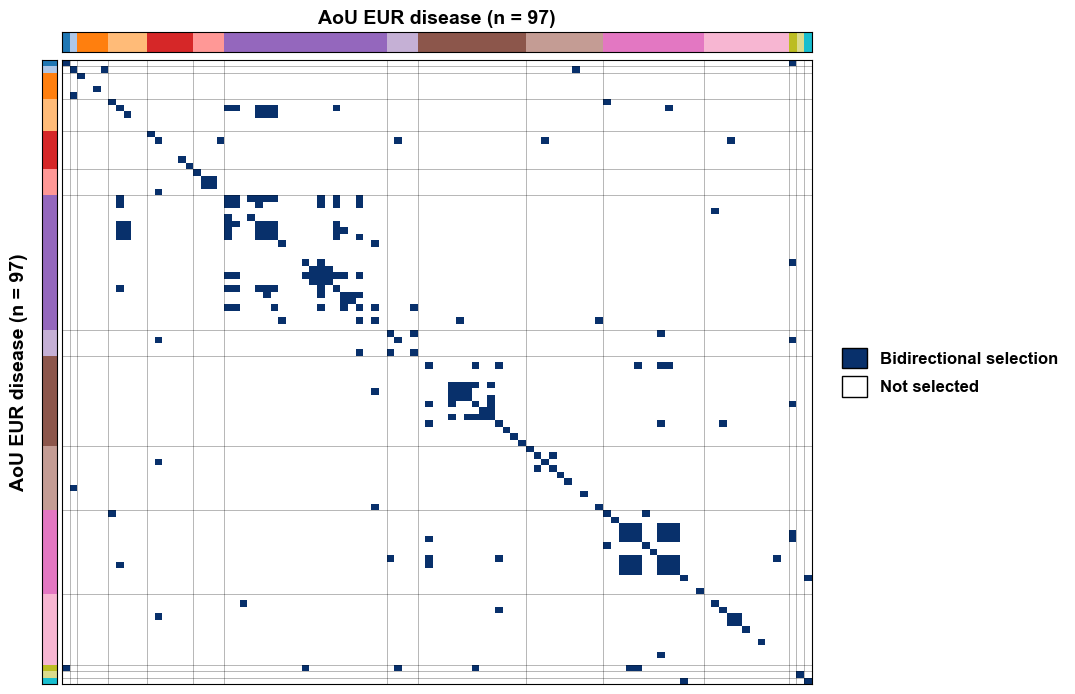

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

row_icd = list(eur_bimatrix.index)
col_icd = list(eur_bimatrix.columns)

row_chapters = [cm.assign_chapter(icd) for icd in row_icd]
col_chapters = [cm.assign_chapter(icd) for icd in col_icd]

row_colors = [cm.chapter2color_map.get(ch) for ch in row_chapters]
col_colors = [cm.chapter2color_map.get(ch) for ch in col_chapters]

# Figure layout
fig = plt.figure(figsize=(10, 8))

ax_colstrip = fig.add_axes([0.09, 0.91, 0.75, 0.025])
ax_rowstrip = fig.add_axes([0.07, 0.12, 0.015, 0.78])
ax_hm       = fig.add_axes([0.09, 0.12, 0.75, 0.78])
# ax_cbar     = fig.add_axes([0.86, 0.22, 0.02, 0.60])

# Row chapter color strip
row_strip_array = np.array([mcolors.to_rgba(c) for c in row_colors]).reshape(len(row_icd), 1, 4)
ax_rowstrip.imshow(row_strip_array, aspect="auto", origin="upper")

ax_rowstrip.set_xticks([])
ax_rowstrip.set_yticks([])
ax_rowstrip.set_ylabel(f"AoU EUR disease (n = {len(row_icd)})", fontsize=14, fontweight="bold", labelpad=10)

# Column chapter color strip
col_strip_array = np.array([mcolors.to_rgba(c) for c in col_colors]).reshape(1, len(col_icd), 4)
ax_colstrip.imshow(col_strip_array, aspect="auto", origin="upper")

ax_colstrip.set_xticks([])
ax_colstrip.set_yticks([])
ax_colstrip.set_title(f"AoU EUR disease (n = {len(col_icd)})", fontsize=14, fontweight="bold", pad=6)

bi_color = "#08306B"
cmap_bin = mcolors.ListedColormap(["white", bi_color])

# Heatmap
sns.heatmap((eur_bimatrix > 0).astype(int), cmap=cmap_bin, vmin=0, vmax=1, ax=ax_hm,
            xticklabels=False, yticklabels=False, cbar=False, rasterized=True)
ax_hm.set_xlabel("")
ax_hm.set_ylabel("")

for _, spine in ax_hm.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Chapter boundaries
row_boundaries = [i for i in range(1, len(row_chapters)) if row_chapters[i] != row_chapters[i - 1]]
col_boundaries = [i for i in range(1, len(col_chapters)) if col_chapters[i] != col_chapters[i - 1]]

for b in row_boundaries:
    ax_hm.axhline(b, color="black", linewidth=0.4, alpha=0.5)

for b in col_boundaries:
    ax_hm.axvline(b, color="black", linewidth=0.4, alpha=0.5)

# Legend: two categories, placed to the right of the heatmap
legend_handles = [
    mpatches.Patch(facecolor=bi_color, edgecolor="black", linewidth=1, label="Bidirectional selection"),
    mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1, label="Not selected"),
]
leg = ax_hm.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
                   frameon=False, fontsize=12, handlelength=1.5, handleheight=1.5)
for text in leg.get_texts():
    text.set_fontweight("bold")

plt.show()

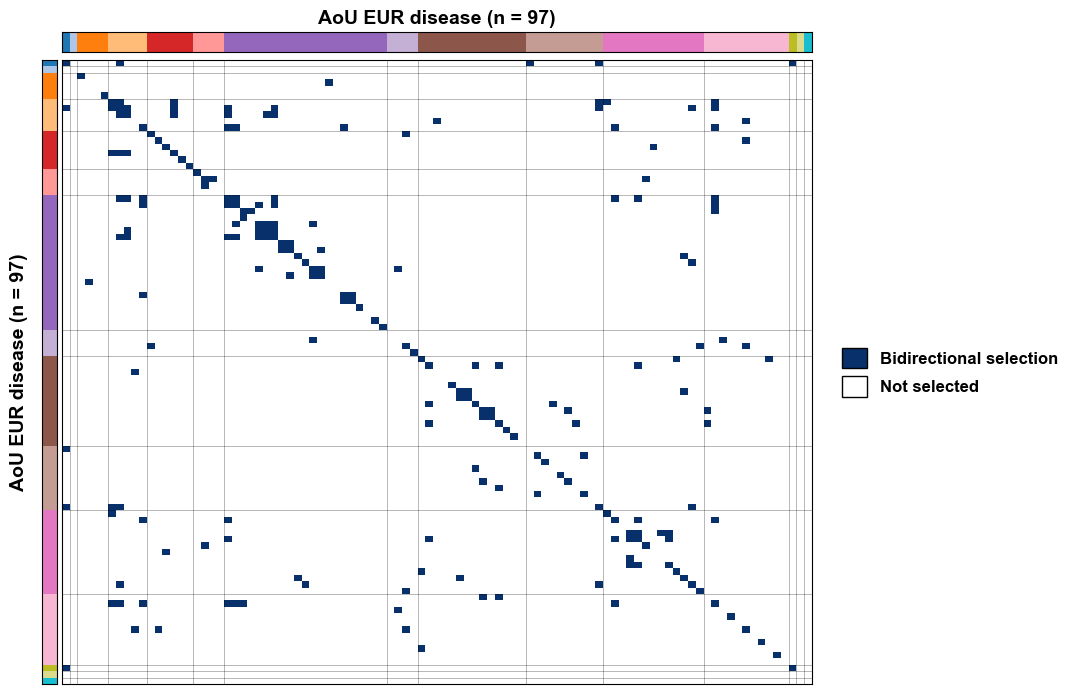

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

row_icd = list(afr_bimatrix.index)
col_icd = list(afr_bimatrix.columns)

row_chapters = [cm.assign_chapter(icd) for icd in row_icd]
col_chapters = [cm.assign_chapter(icd) for icd in col_icd]

row_colors = [cm.chapter2color_map.get(ch) for ch in row_chapters]
col_colors = [cm.chapter2color_map.get(ch) for ch in col_chapters]

# Figure layout
fig = plt.figure(figsize=(10, 8))

ax_colstrip = fig.add_axes([0.09, 0.91, 0.75, 0.025])
ax_rowstrip = fig.add_axes([0.07, 0.12, 0.015, 0.78])
ax_hm       = fig.add_axes([0.09, 0.12, 0.75, 0.78])
# ax_cbar     = fig.add_axes([0.86, 0.22, 0.02, 0.60])

# Row chapter color strip
row_strip_array = np.array([mcolors.to_rgba(c) for c in row_colors]).reshape(len(row_icd), 1, 4)
ax_rowstrip.imshow(row_strip_array, aspect="auto", origin="upper")

ax_rowstrip.set_xticks([])
ax_rowstrip.set_yticks([])
ax_rowstrip.set_ylabel(f"AoU EUR disease (n = {len(row_icd)})", fontsize=14, fontweight="bold", labelpad=10)

# Column chapter color strip
col_strip_array = np.array([mcolors.to_rgba(c) for c in col_colors]).reshape(1, len(col_icd), 4)
ax_colstrip.imshow(col_strip_array, aspect="auto", origin="upper")

ax_colstrip.set_xticks([])
ax_colstrip.set_yticks([])
ax_colstrip.set_title(f"AoU EUR disease (n = {len(col_icd)})", fontsize=14, fontweight="bold", pad=6)

bi_color = "#08306B"
cmap_bin = mcolors.ListedColormap(["white", bi_color])

# Heatmap
sns.heatmap((afr_bimatrix > 0).astype(int), cmap=cmap_bin, vmin=0, vmax=1, ax=ax_hm,
            xticklabels=False, yticklabels=False, cbar=False, rasterized=True)
ax_hm.set_xlabel("")
ax_hm.set_ylabel("")

for _, spine in ax_hm.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Chapter boundaries
row_boundaries = [i for i in range(1, len(row_chapters)) if row_chapters[i] != row_chapters[i - 1]]
col_boundaries = [i for i in range(1, len(col_chapters)) if col_chapters[i] != col_chapters[i - 1]]

for b in row_boundaries:
    ax_hm.axhline(b, color="black", linewidth=0.4, alpha=0.5)

for b in col_boundaries:
    ax_hm.axvline(b, color="black", linewidth=0.4, alpha=0.5)

# Legend: two categories, placed to the right of the heatmap
legend_handles = [
    mpatches.Patch(facecolor=bi_color, edgecolor="black", linewidth=1, label="Bidirectional selection"),
    mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1, label="Not selected"),
]
leg = ax_hm.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
                   frameon=False, fontsize=12, handlelength=1.5, handleheight=1.5)
for text in leg.get_texts():
    text.set_fontweight("bold")

plt.show()

# AOU-UKB EUR clustering

In [12]:
aou_smatrix = aou_bmatrix.copy()
ukb_smatrix = ukb_bmatrix.copy()
print(ukb_smatrix.shape, aou_smatrix.shape)

(368, 368) (368, 368)


In [13]:
### Construct Bidirectional-matrix ###

A = aou_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
aou_bimatrix = pd.DataFrame(M_bi, index=aou_bmatrix.index, columns=aou_bmatrix.index)

A = ukb_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
ukb_bimatrix = pd.DataFrame(M_bi, index=ukb_bmatrix.index, columns=ukb_bmatrix.index)

In [14]:
# Degree = number of reciprocal partners; each cohort keeps its own connected set
aou_degree = (aou_bimatrix > 0).sum(axis=1)
aou_isolated = aou_degree.index[aou_degree == 0].tolist()
aou_connected = aou_degree.index[aou_degree > 0]
aou_bimatrix = aou_bimatrix.loc[aou_connected, aou_connected]

ukb_degree = (ukb_bimatrix > 0).sum(axis=1)
ukb_isolated = ukb_degree.index[ukb_degree == 0].tolist()
ukb_connected = ukb_degree.index[ukb_degree > 0]
ukb_bimatrix = ukb_bimatrix.loc[ukb_connected, ukb_connected]

# Cross-tab of connectivity status on the 368 shared diseases (report in text / ST3)
status = pd.DataFrame({"AoU": np.where(aou_degree > 0, "connected", "isolated"),
                       "UKB": np.where(ukb_degree.reindex(aou_degree.index) > 0, "connected", "isolated")},
                      index=aou_degree.index)
print(pd.crosstab(status["AoU"], status["UKB"], margins=True))

UKB        connected  isolated  All
AoU                                
connected        186        31  217
isolated          49       102  151
All              235       133  368


In [15]:
# calculate eigenvalues and eigenvectors, then sort

from numpy.linalg import eigh

# Eigendecomposition for both cohorts
eigvals_aou, eigvecs_aou = eigh(aou_bimatrix)
eigvals_ukb, eigvecs_ukb = eigh(ukb_bimatrix)

# Sort eigenvalues/vectors descending for each cohort
idx_aou = np.argsort(eigvals_aou)[::-1]
eigvals_aou = eigvals_aou[idx_aou]
eigvecs_aou = eigvecs_aou[:, idx_aou]

idx_ukb = np.argsort(eigvals_ukb)[::-1]
eigvals_ukb = eigvals_ukb[idx_ukb]
eigvecs_ukb = eigvecs_ukb[:, idx_ukb]

d:\miniconda3\envs\BIOSTATS\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\miniconda3\envs\BIOSTATS\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "d:\miniconda3\envs\BIOSTATS\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "d:\miniconda3\envs\BIOSTATS\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "d:\miniconda3\envs\BIOSTATS\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


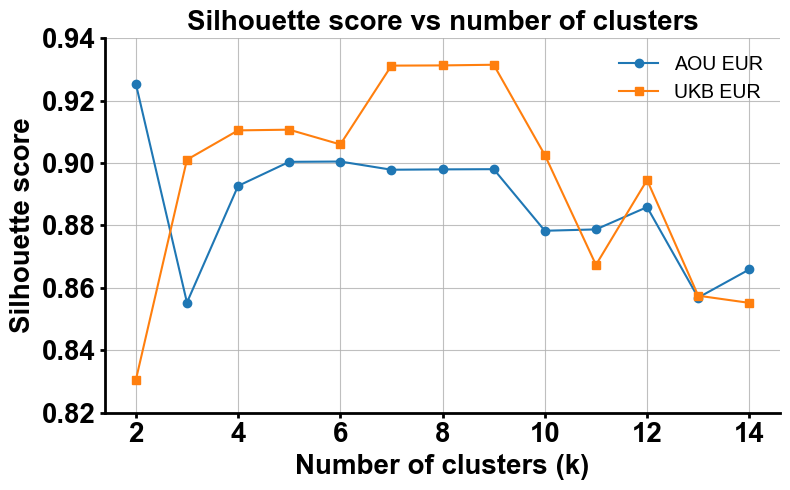

Best k (AoU): 2
Best k (UKB): 9


In [16]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

# Scan over candidate k values for all three cohorts
k_range = range(2, 15)
silhouette_aou = []
silhouette_ukb = []

for k_try in k_range:
    # Spectral embedding -> row-normalize -> KMeans -> silhouette score

    # AoU: top-k eigenvectors, normalize, cluster, score
    features_aou = normalize(eigvecs_aou[:, :k_try], norm="l2")
    labels_aou = KMeans(n_clusters=k_try, random_state=42, n_init=20).fit_predict(features_aou)
    silhouette_aou.append(silhouette_score(features_aou, labels_aou))

    # UKB: top-k eigenvectors, normalize, cluster, score
    features_ukb = normalize(eigvecs_ukb[:, :k_try], norm="l2")
    labels_ukb = KMeans(n_clusters=k_try, random_state=42, n_init=20).fit_predict(features_ukb)
    silhouette_ukb.append(silhouette_score(features_ukb, labels_ukb))

# Plot all three silhouette curves on the same figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(k_range), silhouette_aou, marker="o", label="AOU EUR")
ax.plot(list(k_range), silhouette_ukb, marker="s", label="UKB EUR")
ax.set_xlabel("Number of clusters (k)", fontsize=20, fontweight='bold')
ax.set_ylabel("Silhouette score", fontsize=20, fontweight='bold')
ax.set_title("Silhouette score vs number of clusters", fontsize=20, fontweight='bold')

# Enlarge legend so it is readable alongside 20-pt axis text
ax.legend(fontsize=14, frameon=False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(axis='both', labelsize=20, width=2)
ax.tick_params(which='minor', length=8, width=1.5)
ax.grid(axis='both', alpha=0.8)
ax.set_ylim(0.82, 0.94)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')

plt.tight_layout()
plt.show()

# Best k for each cohort
best_k_aou = list(k_range)[np.argmax(silhouette_aou)]
best_k_ukb = list(k_range)[np.argmax(silhouette_ukb)]
print(f"Best k (AoU): {best_k_aou}")
print(f"Best k (UKB): {best_k_ukb}")

# Clustering

In [17]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

k = 7

# aou #
# Take top-k eigenvectors (largest eigenvalues) as features, Cluster on spectral embedding
features = normalize(eigvecs_aou[:, :k], norm="l2")
labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(features)

aou_cluster_df = pd.DataFrame({"trait": aou_bimatrix.index, "cluster": labels}).sort_values("cluster")
aou_cluster_df["chapter"] = aou_cluster_df["trait"].apply(cm.assign_chapter)
aou_cluster_df["chapter_roman"] = aou_cluster_df["chapter"].map(cm.chapter2roman_map)

# ukb #
features = normalize(eigvecs_ukb[:, :k], norm="l2")
labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(features)

ukb_cluster_df = pd.DataFrame({"trait": ukb_bimatrix.index, "cluster": labels}).sort_values("cluster")
ukb_cluster_df["chapter"] = ukb_cluster_df["trait"].apply(cm.assign_chapter)
ukb_cluster_df["chapter_roman"] = ukb_cluster_df["chapter"].map(cm.chapter2roman_map)

In [18]:
from itertools import combinations
import numpy as np

def repel_overlapping_nodes(pos, min_dist=0.35, n_iter=100, step=0.5):
    pos = {k: np.array(v, dtype=float) for k, v in pos.items()}

    for _ in range(n_iter):
        for u, v in combinations(pos.keys(), 2):
            delta = pos[u] - pos[v]
            dist = np.linalg.norm(delta)

            if dist < 1e-8:
                delta = np.random.normal(size=2)
                dist = np.linalg.norm(delta)

            if dist < min_dist:
                move = (min_dist - dist) * delta / dist * step
                pos[u] += move
                pos[v] -= move

    return pos

In [19]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from textwrap import fill

matplotlib.rcParams["font.family"] = "Arial"


def plot_one_cluster_network(cohort="aou", cluster_id=0, min_edge_weight=0, label_top_n=5, seed=42, figsize=(5, 5), save_path=None):
    """
    Visualize one selected cluster from AoU or UKB.

    Required global variables:
        aou_bimatrix, ukb_bimatrix
        aou_cluster_df, ukb_cluster_df
        icd_list
        roman2color_map
    """

    # Select data
    if cohort.lower() == "aou":
        bimatrix = aou_bimatrix
        cluster_df = aou_cluster_df
        title_prefix = "AoU EUR"
    elif cohort.lower() == "ukb":
        bimatrix = ukb_bimatrix
        cluster_df = ukb_cluster_df
        title_prefix = "UKB EUR"
    else:
        raise ValueError("cohort must be 'aou', or 'ukb'")
    sub_df = cluster_df[cluster_df["cluster"] == cluster_id].copy()
    traits = sub_df["trait"].tolist()

    if len(traits) == 0:
        raise ValueError(f"No traits found for {cohort} cluster {cluster_id}")

    idx = [list(bimatrix.index).index(t) for t in traits]

    A = np.asarray(bimatrix)[np.ix_(idx, idx)].copy()
    np.fill_diagonal(A, 0)

    # remove negative / weak edges
    A[A <= min_edge_weight] = 0

    # Build graph
    G = nx.Graph()

    for _, row in sub_df.iterrows():
        G.add_node(row["trait"], chapter=row["chapter"], chapter_roman=row["chapter_roman"])

    for i in range(len(traits)):
        for j in range(i + 1, len(traits)):
            if A[i, j] > 0:
                G.add_edge(traits[i], traits[j], weight=A[i, j])

    # Layout
    if G.number_of_edges() > 0:
        pos = nx.spring_layout(
            G,
            seed=seed,
            weight=None,
            k=0.8,
            iterations=1000,
        )
        pos = {n: p * 3.0 for n, p in pos.items()}
        pos = repel_overlapping_nodes(pos, min_dist=1.0, n_iter=200)
    else:
        pos = nx.circular_layout(G)

    # Node / edge aesthetics
    node_colors = [cm.roman2color_map.get(G.nodes[n]["chapter_roman"]) for n in G.nodes()]
    degrees = dict(G.degree())
    node_sizes = [600 + 200 * degrees[n] for n in G.nodes()]

    if G.number_of_edges() > 0:
        weights = np.array([G[u][v]["weight"] for u, v in G.edges()])
        edge_widths = (3.0 + 4.5 * (weights - weights.min()) / (weights.max() - weights.min() + 1e-8))
    else:
        edge_widths = []

    # Identify top-degree nodes and set per-node border width
    top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:label_top_n] if label_top_n > 0 else []
    top_nodes = [n for n in top_nodes if degrees[n] > 0]

    # Thicker black outline highlights the hub nodes within the cluster
    node_linewidths = [2.5 if n in top_nodes else 0.5 for n in G.nodes()]
    
    # Plot
    fig, ax = plt.subplots(figsize=figsize)

    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        edge_color="gray",
        width=edge_widths,
        alpha=0.8
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_color=node_colors,
        node_size=node_sizes,
        edgecolors="black",
        linewidths=node_linewidths,
    )

    # Label ALL nodes with their ICD code
    labels = {n: n for n in G.nodes()}

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        ax=ax,
        font_size=13,        # smaller font so labels fit inside nodes
        font_weight="bold"
    )
    
    # Dominant chapter of this cluster, used as the panel title
    dominant_chapter = sub_df["chapter"].value_counts().idxmax()
    title = f"{dominant_chapter}-enriched cluster (N={G.number_of_nodes()})"

    # Wrap long chapter names, then pad to a fixed number of lines so titles align across panels
    title_lines = fill(title, width=30).split("\n")
    n_title_lines = 3
    title_lines = title_lines + [" "] * (n_title_lines - len(title_lines))
    ax.set_title("\n".join(title_lines), fontsize=20, fontweight="bold", va="bottom")
    ax.axis("off")   # hide axes frame, ticks and background
    
    plt.tight_layout()

    # Save to disk if a path is given, then close to avoid accumulating open figures in the loop
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

    return G

In [20]:
# example output
G = plot_one_cluster_network(
    cohort="ukb",
    cluster_id=6,
    min_edge_weight=0,
    label_top_n=5,
    figsize=(5, 5)
)

# Significant enrich clustering

In [21]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

enrich_records = []
for cohort, cdf in [("AoU EUR", aou_cluster_df), ("UKB EUR", ukb_cluster_df)]:
    n_total = len(cdf)
    for cl in sorted(cdf["cluster"].unique()):
        in_cl = cdf["cluster"] == cl
        for chap in cdf["chapter_roman"].dropna().unique():
            in_ch = cdf["chapter_roman"] == chap

            # 2x2 table: rows = in/out of community, columns = in/out of chapter
            a = int((in_cl & in_ch).sum())
            b = int((in_cl & ~in_ch).sum())
            c = int((~in_cl & in_ch).sum())
            d = int((~in_cl & ~in_ch).sum())

            # One-sided Fisher's exact test for over-representation of the chapter in the community
            odds, p = fisher_exact([[a, b], [c, d]], alternative="greater")
            enrich_records.append({"cohort": cohort, "cluster": cl, "chapter": chap,
                                   "n_cluster": int(in_cl.sum()), "n_overlap": a,
                                   "n_chapter": int(in_ch.sum()), "odds_ratio": odds, "p": p})

enrich_df = pd.DataFrame(enrich_records)

# BH FDR across all community x chapter pairs, separately within each cohort
enrich_df["q"] = np.nan
for cohort in enrich_df["cohort"].unique():
    m = enrich_df["cohort"] == cohort
    enrich_df.loc[m, "q"] = multipletests(enrich_df.loc[m, "p"], method="fdr_bh")[1]
enrich_df["sig"] = enrich_df["q"] < 0.05

# Summary: number of communities with >= 1 significantly enriched chapter
summary = enrich_df.groupby(["cohort", "cluster"])["sig"].any().groupby("cohort").agg(["sum", "count"])
summary.columns = ["n_enriched", "n_communities"]
print(summary)

# Per-community detail: significant chapters (sorted by q), for the text and a supplementary table
sig_df = enrich_df[enrich_df["sig"]].sort_values(["cohort", "cluster", "q"])
print(sig_df[["cohort", "cluster", "n_cluster", "chapter", "n_overlap", "n_chapter", "odds_ratio", "q"]]
      .round({"odds_ratio": 2}).to_string(index=False))

# Communities with no enriched chapter (to describe in the text)
no_sig = enrich_df.groupby(["cohort", "cluster"])["sig"].any()
print(no_sig[~no_sig])

         n_enriched  n_communities
cohort                            
AoU EUR           7              7
UKB EUR           7              7
 cohort  cluster  n_cluster chapter  n_overlap  n_chapter  odds_ratio            q
AoU EUR        0        153      XI         22         22         inf 6.257677e-03
AoU EUR        0        153      II         20         20         inf 1.032217e-02
AoU EUR        0        153     XIV         19         19         inf 1.355748e-02
AoU EUR        1         10     XIX          7          8      480.67 2.822942e-08
AoU EUR        2         20      IX         13         24       31.40 2.822942e-08
AoU EUR        3         10      IV          4         10       22.33 8.124569e-03
AoU EUR        4          9    XIII          7         25       36.94 1.207302e-04
AoU EUR        5          8       V          7         11      358.75 2.822942e-08
AoU EUR        6          7    XIII          5         25       23.75 6.257677e-03
UKB EUR        0         21   

# EUR-AFR AOU clustering

In [22]:
eur_smatrix = aou_afr_bmatrix.copy()
afr_smatrix = afr_bmatrix.copy()
print(eur_smatrix.shape, afr_smatrix.shape)

(97, 97) (97, 97)


In [23]:
### Construct Bidirectional-matrix ###

A = eur_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
eur_bimatrix = pd.DataFrame(M_bi, index=aou_afr_bmatrix.index, columns=aou_afr_bmatrix.index)

A = afr_smatrix.values  # row selects column (target=row, candidate=column)
bidirectional_mask = (A > 0) & (A.T > 0)
# average selection strength between i -> j and j -> i
M_avg = (A + A.T) / 2
# keep only bidirectional pairs
M_bi = np.where(bidirectional_mask, M_avg, 0)
afr_bimatrix = pd.DataFrame(M_bi, index=afr_bmatrix.index, columns=afr_bmatrix.index)

In [24]:
# Degree = number of reciprocal partners; each cohort keeps its own connected set
eur_degree = (eur_bimatrix > 0).sum(axis=1)
eur_isolated = eur_degree.index[eur_degree == 0].tolist()
eur_connected = eur_degree.index[eur_degree > 0]
eur_bimatrix = eur_bimatrix.loc[eur_connected, eur_connected]

afr_degree = (afr_bimatrix > 0).sum(axis=1)
afr_isolated = afr_degree.index[afr_degree == 0].tolist()
afr_connected = afr_degree.index[afr_degree > 0]
afr_bimatrix = afr_bimatrix.loc[afr_connected, afr_connected]

# Cross-tab of connectivity status on the 368 shared diseases (report in text / ST3)
status = pd.DataFrame({"EUR": np.where(eur_degree > 0, "connected", "isolated"),
                       "AFR": np.where(afr_degree.reindex(afr_degree.index) > 0, "connected", "isolated")},
                      index=afr_degree.index)
print(pd.crosstab(status["EUR"], status["AFR"], margins=True))

AFR        connected  isolated  All
EUR                                
connected         68        10   78
isolated          14         5   19
All               82        15   97


In [25]:
# calculate eigenvalues and eigenvectors, then sort

from numpy.linalg import eigh

# Eigendecomposition for both cohorts
eigvals_eur, eigvecs_eur = eigh(eur_bimatrix)
eigvals_afr, eigvecs_afr = eigh(afr_bimatrix)

# Sort eigenvalues/vectors descending for each cohort
idx_aou = np.argsort(eigvals_eur)[::-1]
eigvals_eur = eigvals_eur[idx_aou]
eigvecs_eur = eigvecs_eur[:, idx_aou]

idx_ukb = np.argsort(eigvals_afr)[::-1]
eigvals_afr = eigvals_afr[idx_ukb]
eigvecs_afr = eigvecs_afr[:, idx_ukb]

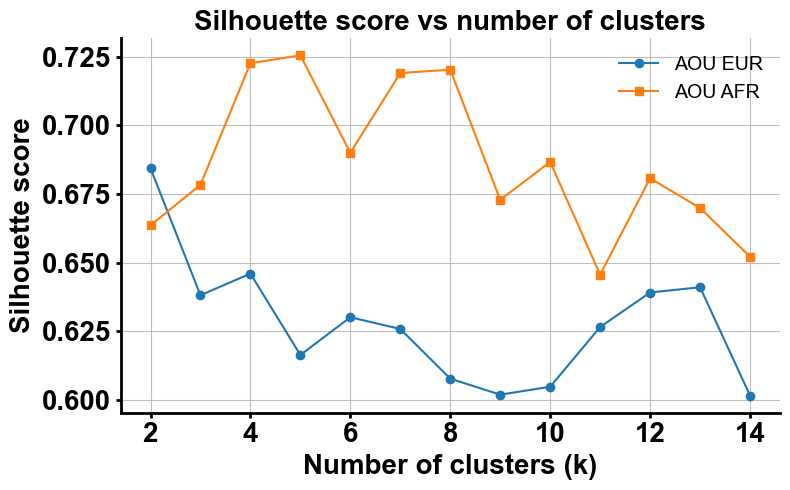

Best k (AoU EUR): 2
Best k (AoU AFR): 5


In [26]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

# Scan over candidate k values for all three cohorts
k_range = range(2, 15)
silhouette_eur = []
silhouette_afr = []

for k_try in k_range:
    # Spectral embedding -> row-normalize -> KMeans -> silhouette score

    # AoU: top-k eigenvectors, normalize, cluster, score
    features_aou = normalize(eigvecs_eur[:, :k_try], norm="l2")
    labels_aou = KMeans(n_clusters=k_try, random_state=42, n_init=20).fit_predict(features_aou)
    silhouette_eur.append(silhouette_score(features_aou, labels_aou))

    # UKB: top-k eigenvectors, normalize, cluster, score
    features_ukb = normalize(eigvecs_afr[:, :k_try], norm="l2")
    labels_ukb = KMeans(n_clusters=k_try, random_state=42, n_init=20).fit_predict(features_ukb)
    silhouette_afr.append(silhouette_score(features_ukb, labels_ukb))

# Plot all three silhouette curves on the same figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(k_range), silhouette_eur, marker="o", label="AOU EUR")
ax.plot(list(k_range), silhouette_afr, marker="s", label="AOU AFR")
ax.set_xlabel("Number of clusters (k)", fontsize=20, fontweight='bold')
ax.set_ylabel("Silhouette score", fontsize=20, fontweight='bold')
ax.set_title("Silhouette score vs number of clusters", fontsize=20, fontweight='bold')

# Enlarge legend so it is readable alongside 20-pt axis text
ax.legend(fontsize=14, frameon=False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.tick_params(axis='both', labelsize=20, width=2)
ax.tick_params(which='minor', length=8, width=1.5)
ax.grid(axis='both', alpha=0.8)
# ax.set_ylim(0.88, 0.96)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')

plt.tight_layout()
plt.show()

# Best k for each cohort
best_k_aou = list(k_range)[np.argmax(silhouette_eur)]
best_k_ukb = list(k_range)[np.argmax(silhouette_afr)]
print(f"Best k (AoU EUR): {best_k_aou}")
print(f"Best k (AoU AFR): {best_k_ukb}")

In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

k = 4

# aou #
# Take top-k eigenvectors (largest eigenvalues) as features, Cluster on spectral embedding
features = normalize(eigvecs_eur[:, :k], norm="l2")
labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(features)

eur_cluster_df = pd.DataFrame({"trait": eur_bimatrix.index, "cluster": labels}).sort_values("cluster")
eur_cluster_df["chapter"] = eur_cluster_df["trait"].apply(cm.assign_chapter)
eur_cluster_df["chapter_roman"] = eur_cluster_df["chapter"].map(cm.chapter2roman_map)

# ukb #
features = normalize(eigvecs_afr[:, :k], norm="l2")
labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(features)

afr_cluster_df = pd.DataFrame({"trait": afr_bimatrix.index, "cluster": labels}).sort_values("cluster")
afr_cluster_df["chapter"] = afr_cluster_df["trait"].apply(cm.assign_chapter)
afr_cluster_df["chapter_roman"] = afr_cluster_df["chapter"].map(cm.chapter2roman_map)

# Significant enrich clustering

In [28]:
# Swap cluster labels 0 and 3 in AoU EUR so the circulatory-enriched community is cluster 0 in both ancestries
swap_map = {0: 3, 3: 0}
eur_cluster_df["cluster"] = eur_cluster_df["cluster"].replace(swap_map)
print(eur_cluster_df.groupby("cluster").size())

cluster
0     9
1    33
2    12
3    24
dtype: int64


In [29]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

enrich_records = []
for cohort, cdf in [("AoU EUR", eur_cluster_df), ("AoU AFR", afr_cluster_df)]:
    n_total = len(cdf)
    for cl in sorted(cdf["cluster"].unique()):
        in_cl = cdf["cluster"] == cl
        for chap in cdf["chapter_roman"].dropna().unique():
            in_ch = cdf["chapter_roman"] == chap

            # 2x2 table: rows = in/out of community, columns = in/out of chapter
            a = int((in_cl & in_ch).sum())
            b = int((in_cl & ~in_ch).sum())
            c = int((~in_cl & in_ch).sum())
            d = int((~in_cl & ~in_ch).sum())

            # One-sided Fisher's exact test for over-representation of the chapter in the community
            odds, p = fisher_exact([[a, b], [c, d]], alternative="greater")
            enrich_records.append({"cohort": cohort, "cluster": cl, "chapter": chap,
                                   "n_cluster": int(in_cl.sum()), "n_overlap": a,
                                   "n_chapter": int(in_ch.sum()), "odds_ratio": odds, "p": p})

enrich_df = pd.DataFrame(enrich_records)

# BH FDR across all community x chapter pairs, separately within each cohort
enrich_df["q"] = np.nan
for cohort in enrich_df["cohort"].unique():
    m = enrich_df["cohort"] == cohort
    enrich_df.loc[m, "q"] = multipletests(enrich_df.loc[m, "p"], method="fdr_bh")[1]
enrich_df["sig"] = enrich_df["q"] < 0.05

# Summary: number of communities with >= 1 significantly enriched chapter
summary = enrich_df.groupby(["cohort", "cluster"])["sig"].any().groupby("cohort").agg(["sum", "count"])
summary.columns = ["n_enriched", "n_communities"]
print(summary)

# Per-community detail: significant chapters (sorted by q), for the text and a supplementary table
sig_df = enrich_df[enrich_df["sig"]].sort_values(["cohort", "cluster", "q"])
print(sig_df[["cohort", "cluster", "n_cluster", "chapter", "n_overlap", "n_chapter", "odds_ratio", "q"]]
      .round({"odds_ratio": 2}).to_string(index=False))

# Communities with no enriched chapter (to describe in the text)
no_sig = enrich_df.groupby(["cohort", "cluster"])["sig"].any()
print(no_sig[~no_sig])

         n_enriched  n_communities
cohort                            
AoU AFR           1              4
AoU EUR           1              4
 cohort  cluster  n_cluster chapter  n_overlap  n_chapter  odds_ratio        q
AoU AFR        0         10      IX          7         19       11.67 0.048341
AoU EUR        0          9      IX          7         17       20.65 0.012205
cohort   cluster
AoU AFR  1          False
         2          False
         3          False
AoU EUR  1          False
         2          False
         3          False
Name: sig, dtype: bool


# Clustering

In [30]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from textwrap import fill

matplotlib.rcParams["font.family"] = "Arial"


def plot_one_cluster_network(cohort="eur", cluster_id=0, min_edge_weight=0, label_top_n=5, seed=42, figsize=(5, 5), save_path=None):
    """
    Visualize one selected cluster from AoU or UKB.

    Required global variables:
        aou_bimatrix, ukb_bimatrix
        aou_cluster_df, ukb_cluster_df
        icd_list
        roman2color_map
    """

    # Select data
    if cohort.lower() == "eur":
        bimatrix = eur_bimatrix
        cluster_df = eur_cluster_df
        title_prefix = "AoU EUR"
    elif cohort.lower() == "afr":
        bimatrix = afr_bimatrix
        cluster_df = afr_cluster_df
        title_prefix = "AoU AFR"
    else:
        raise ValueError("cohort must be 'eur', or 'afr'")
    sub_df = cluster_df[cluster_df["cluster"] == cluster_id].copy()
    traits = sub_df["trait"].tolist()

    if len(traits) == 0:
        raise ValueError(f"No traits found for {cohort} cluster {cluster_id}")

    idx = [list(bimatrix.index).index(t) for t in traits]

    A = np.asarray(bimatrix)[np.ix_(idx, idx)].copy()
    np.fill_diagonal(A, 0)

    # remove negative / weak edges
    A[A <= min_edge_weight] = 0

    # Build graph
    G = nx.Graph()

    for _, row in sub_df.iterrows():
        G.add_node(row["trait"], chapter=row["chapter"], chapter_roman=row["chapter_roman"])

    for i in range(len(traits)):
        for j in range(i + 1, len(traits)):
            if A[i, j] > 0:
                G.add_edge(traits[i], traits[j], weight=A[i, j])

    # Layout
    if G.number_of_edges() > 0:
        pos = nx.spring_layout(
            G,
            seed=seed,
            weight=None,
            k=0.8,
            iterations=1000,
        )
        pos = {n: p * 3.0 for n, p in pos.items()}
        pos = repel_overlapping_nodes(pos, min_dist=1.0, n_iter=200)
    else:
        pos = nx.circular_layout(G)

    # Node / edge aesthetics
    node_colors = [cm.roman2color_map.get(G.nodes[n]["chapter_roman"]) for n in G.nodes()]
    degrees = dict(G.degree())
    node_sizes = [600 + 200 * degrees[n] for n in G.nodes()]

    if G.number_of_edges() > 0:
        weights = np.array([G[u][v]["weight"] for u, v in G.edges()])
        edge_widths = (3.0 + 4.5 * (weights - weights.min()) / (weights.max() - weights.min() + 1e-8))
    else:
        edge_widths = []

    # Identify top-degree nodes and set per-node border width
    top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:label_top_n] if label_top_n > 0 else []
    top_nodes = [n for n in top_nodes if degrees[n] > 0]

    # Thicker black outline highlights the hub nodes within the cluster
    node_linewidths = [2.5 if n in top_nodes else 0.5 for n in G.nodes()]
    
    # Plot
    fig, ax = plt.subplots(figsize=figsize)

    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        edge_color="gray",
        width=edge_widths,
        alpha=0.8
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_color=node_colors,
        node_size=node_sizes,
        edgecolors="black",
        linewidths=node_linewidths,
    )

    # Label ALL nodes with their ICD code
    labels = {n: n for n in G.nodes()}

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        ax=ax,
        font_size=13,        # smaller font so labels fit inside nodes
        font_weight="bold"
    )
    
    # Significantly enriched chapters (BH q < 0.05) for this cohort and cluster, from the global enrich_df
    cl_sig = enrich_df[(enrich_df["cohort"] == title_prefix)
                       & (enrich_df["cluster"] == cluster_id)
                       & (enrich_df["sig"])]

    # Title: most significant enriched chapter if any, otherwise a generic cluster label
    if len(cl_sig) > 0:
        top_roman = cl_sig.sort_values("q").iloc[0]["chapter"]
        roman2chapter = {v: k for k, v in cm.chapter2roman_map.items()}
        title = f"{roman2chapter[top_roman]}-enriched cluster (N={G.number_of_nodes()})"
    else:
        title = f"Cluster {cluster_id} (N={G.number_of_nodes()})"

    # Wrap long chapter names, then pad to a fixed number of lines so titles align across panels
    title_lines = fill(title, width=30).split("\n")
    n_title_lines = 3
    title_lines = title_lines + [" "] * (n_title_lines - len(title_lines))
    ax.set_title("\n".join(title_lines), fontsize=20, fontweight="bold", va="bottom")
    ax.axis("off")   # hide axes frame, ticks and background
    
    plt.tight_layout()

    # Save to disk if a path is given, then close to avoid accumulating open figures in the loop
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

    return G